In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [14]:
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.size": 16
    }
)

In [10]:
fname_results = "../experiment_results.csv"
df_all = pd.read_csv(fname_results)
df_all.head()

,id,seq,dist_azo,activity_37,activity_60,wt_id,region,sb_score,dca_energy
0,MARTIN_wt_2_mut_lowDCA_lowSB_beta1.25_sb-3.00_...,GUGCAUUCCGUCGGGAAACCACCGAAUGGCUGUUGUCAAAUUCGGU...,28,-2.982426,-3.578521,2.0,lowDCA_lowSB,4.724404,76.87851
1,MARTIN_wt_2_mut_lowDCA_lowSB_beta1.25_sb-3.00_696,GUGCAUUCCGUCGGGAAACCACCGAAUGGAUGUUGUCAAAUUCGGU...,25,-2.646676,-3.208042,2.0,lowDCA_lowSB,5.871308,79.71062
2,MARTIN_wt_2_mut_lowDCA_lowSB_beta1.25_sb-3.00_910,GUGCAUUCCGCCGGGAAACCACUGAAUGGCUGUUGUCAAAUUCGGU...,27,-0.592556,-2.084677,2.0,lowDCA_lowSB,9.615535,76.88864
3,MARTIN_wt_2_mut_lowDCA_lowSB_beta1.25_sb-3.00_545,GUGCAUUCCGUCGGGAAACCACCGAAUGGCUGUUGUCAAAUUCGGU...,29,-2.463253,-3.154773,2.0,lowDCA_lowSB,4.109425,74.89435
4,MARTIN_wt_2_mut_lowDCA_lowSB_beta1.25_sb-3.00_...,GUGCAUUUCGUCGGGAAACCACCGAAUGGCUGUUGUCAAAUUCGGU...,25,-1.349940,-2.098292,2.0,lowDCA_lowSB,9.580202,75.90297


In [11]:
df_overlap = df_all[df_all["region"] == "overlap"]
print(df_overlap.shape)

mask_overlap_60 = df_overlap["activity_60"] != -5
df_overlap_masked_60 = df_overlap[mask_overlap_60]
print(df_overlap_masked_60.shape)

mask_overlap_37 = df_overlap["activity_37"] != -5
df_overlap_masked_37 = df_overlap[mask_overlap_37]
print(df_overlap_masked_37.shape)

mean_activity_overlap_60 = df_overlap_masked_60["activity_60"].mean()
mean_activity_overlap_37 = df_overlap_masked_37["activity_37"].mean()
print(f"Mean activity in overlap region (60): {mean_activity_overlap_60:.2f}")
print(f"Mean activity in overlap region (37): {mean_activity_overlap_37:.2f}")

(355, 9)
(348, 9)
(349, 9)
Mean activity in overlap region (60): -0.19
Mean activity in overlap region (37): 0.03


In [12]:
mask_detected_37 = df_all["activity_37"] != -5
mask_detected_60 = df_all["activity_60"] != -5

df_all.loc[mask_detected_37, "activity_37"] -= mean_activity_overlap_37
df_all.loc[mask_detected_60, "activity_60"] -= mean_activity_overlap_60

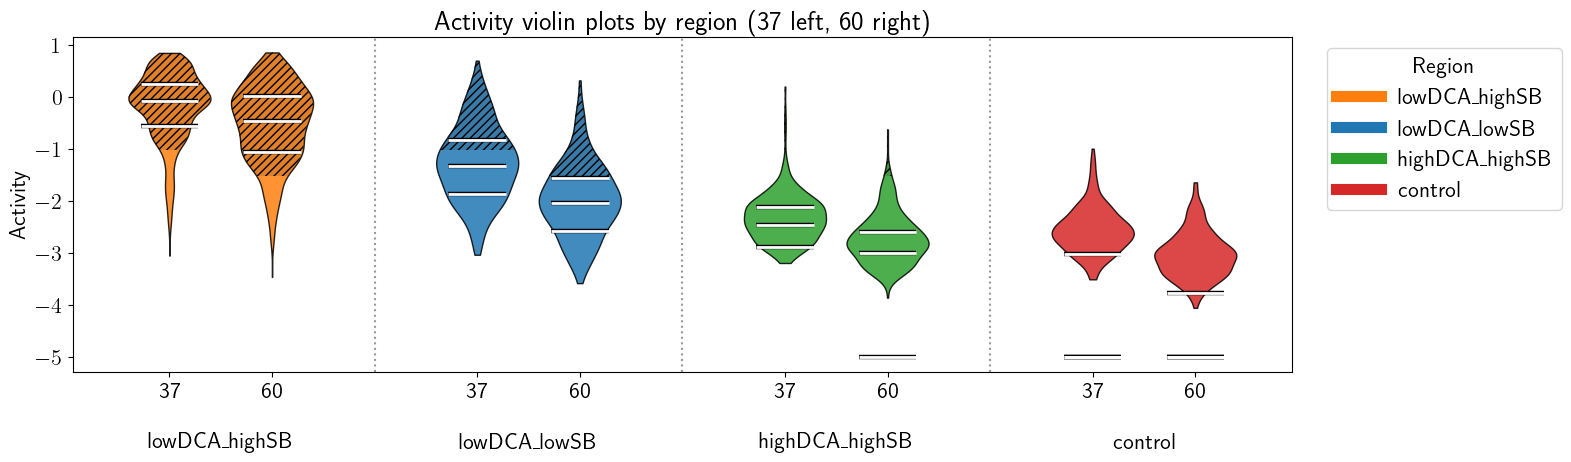

In [28]:
import matplotlib.patheffects as pe

regions = ["lowDCA_highSB", "lowDCA_lowSB", "highDCA_highSB", "control"]

tab10 = sns.color_palette("tab10")
region_colors = [tab10[1], tab10[0], tab10[2], tab10[3]]  # orange, blue, green, red
palette = dict(zip(regions, region_colors))

# 10th percentiles in overlap region, excluding undetected values (-5).
df_overlap = df_all[df_all["region"] == "overlap"]
overlap_37 = df_overlap.loc[df_overlap["activity_37"] != -5, "activity_37"].dropna().values
overlap_60 = df_overlap.loc[df_overlap["activity_60"] != -5, "activity_60"].dropna().values

p10_overlap = {
    "activity_37": np.percentile(overlap_37, 10) if len(overlap_37) > 0 else np.nan,
    "activity_60": np.percentile(overlap_60, 10) if len(overlap_60) > 0 else np.nan,
}

fig, ax = plt.subplots(figsize=(16, 5))

positions = []
labels = []
pair_centers = []
current_pos = 0
violin_metadata = []

for region in regions:
    region_df = df_all[df_all["region"] == region]

    left_pos = current_pos
    right_pos = current_pos + 1
    pair_centers.append((left_pos + right_pos) / 2)

    for pos, col, short_label in [(left_pos, "activity_37", "37"), (right_pos, "activity_60", "60")]:
        # Violin excludes undetected values (-5).
        violin_values = region_df.loc[region_df[col] != -5, col].dropna().values
        if len(violin_values) > 0:
            vp = ax.violinplot(
                dataset=[violin_values],
                positions=[pos],
                widths=0.8,
                showmeans=False,
                showextrema=False,
                showmedians=False,
            )

            for body in vp["bodies"]:
                body.set_facecolor(palette[region])
                body.set_edgecolor("black")
                body.set_alpha(0.85)
                violin_metadata.append((body, pos, col))

        # Percentiles include all values, including -5.
        pct_values = region_df[col].dropna().values
        if len(pct_values) > 0:
            q25, q50, q75 = np.percentile(pct_values, [25, 50, 75])
            pct_lines = ax.hlines(
                [q25, q50, q75],
                pos - 0.28,
                pos + 0.28,
                colors="white",
                linestyles="-",
                linewidth=2.0,
                zorder=6,
            )
            pct_lines.set_path_effects([
                pe.Stroke(linewidth=3.2, foreground="black"),
                pe.Normal(),
            ])

        positions.append(pos)
        labels.append(short_label)

    current_pos += 3

# Add shaded region inside each violin above the overlap 10th-percentile threshold.
ymax = ax.get_ylim()[1]
for body, pos, col in violin_metadata:
    threshold = p10_overlap[col]
    if np.isnan(threshold):
        continue

    # Base translucent fill.
    shade_fill = plt.Rectangle(
        (pos - 0.4, threshold),
        0.8,
        ymax - threshold,
        facecolor="black",
        alpha=0.12,
        edgecolor="none",
        zorder=3,
    )
    shade_fill.set_clip_path(body.get_paths()[0], transform=body.get_transform())
    ax.add_patch(shade_fill)

    # Diagonal hatch overlay for stronger visibility.
    shade_hatch = plt.Rectangle(
        (pos - 0.4, threshold),
        0.8,
        ymax - threshold,
        facecolor="none",
        edgecolor="black",
        hatch="////",
        linewidth=0,
        zorder=4,
    )
    shade_hatch.set_clip_path(body.get_paths()[0], transform=body.get_transform())
    ax.add_patch(shade_hatch)

# Vertical separators between region pairs.
for x_sep in [2, 5, 8]:
    ax.axvline(x=x_sep, color="gray", linestyle=":", linewidth=1.5, alpha=0.8)

ax.set_xticks(positions)
ax.set_xticklabels(labels)
ax.set_ylabel("Activity")
ax.set_xlabel("")
ax.set_title("Activity violin plots by region (37 left, 60 right)")

# Region labels centered under each pair.
for center, region in zip(pair_centers, regions):
    ax.text(center, -0.18, region, transform=ax.get_xaxis_transform(), ha="center", va="top")

legend_handles = [
    plt.Line2D([0], [0], color=palette[region], lw=8, label=region)
    for region in regions
]
ax.legend(handles=legend_handles, title="Region", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

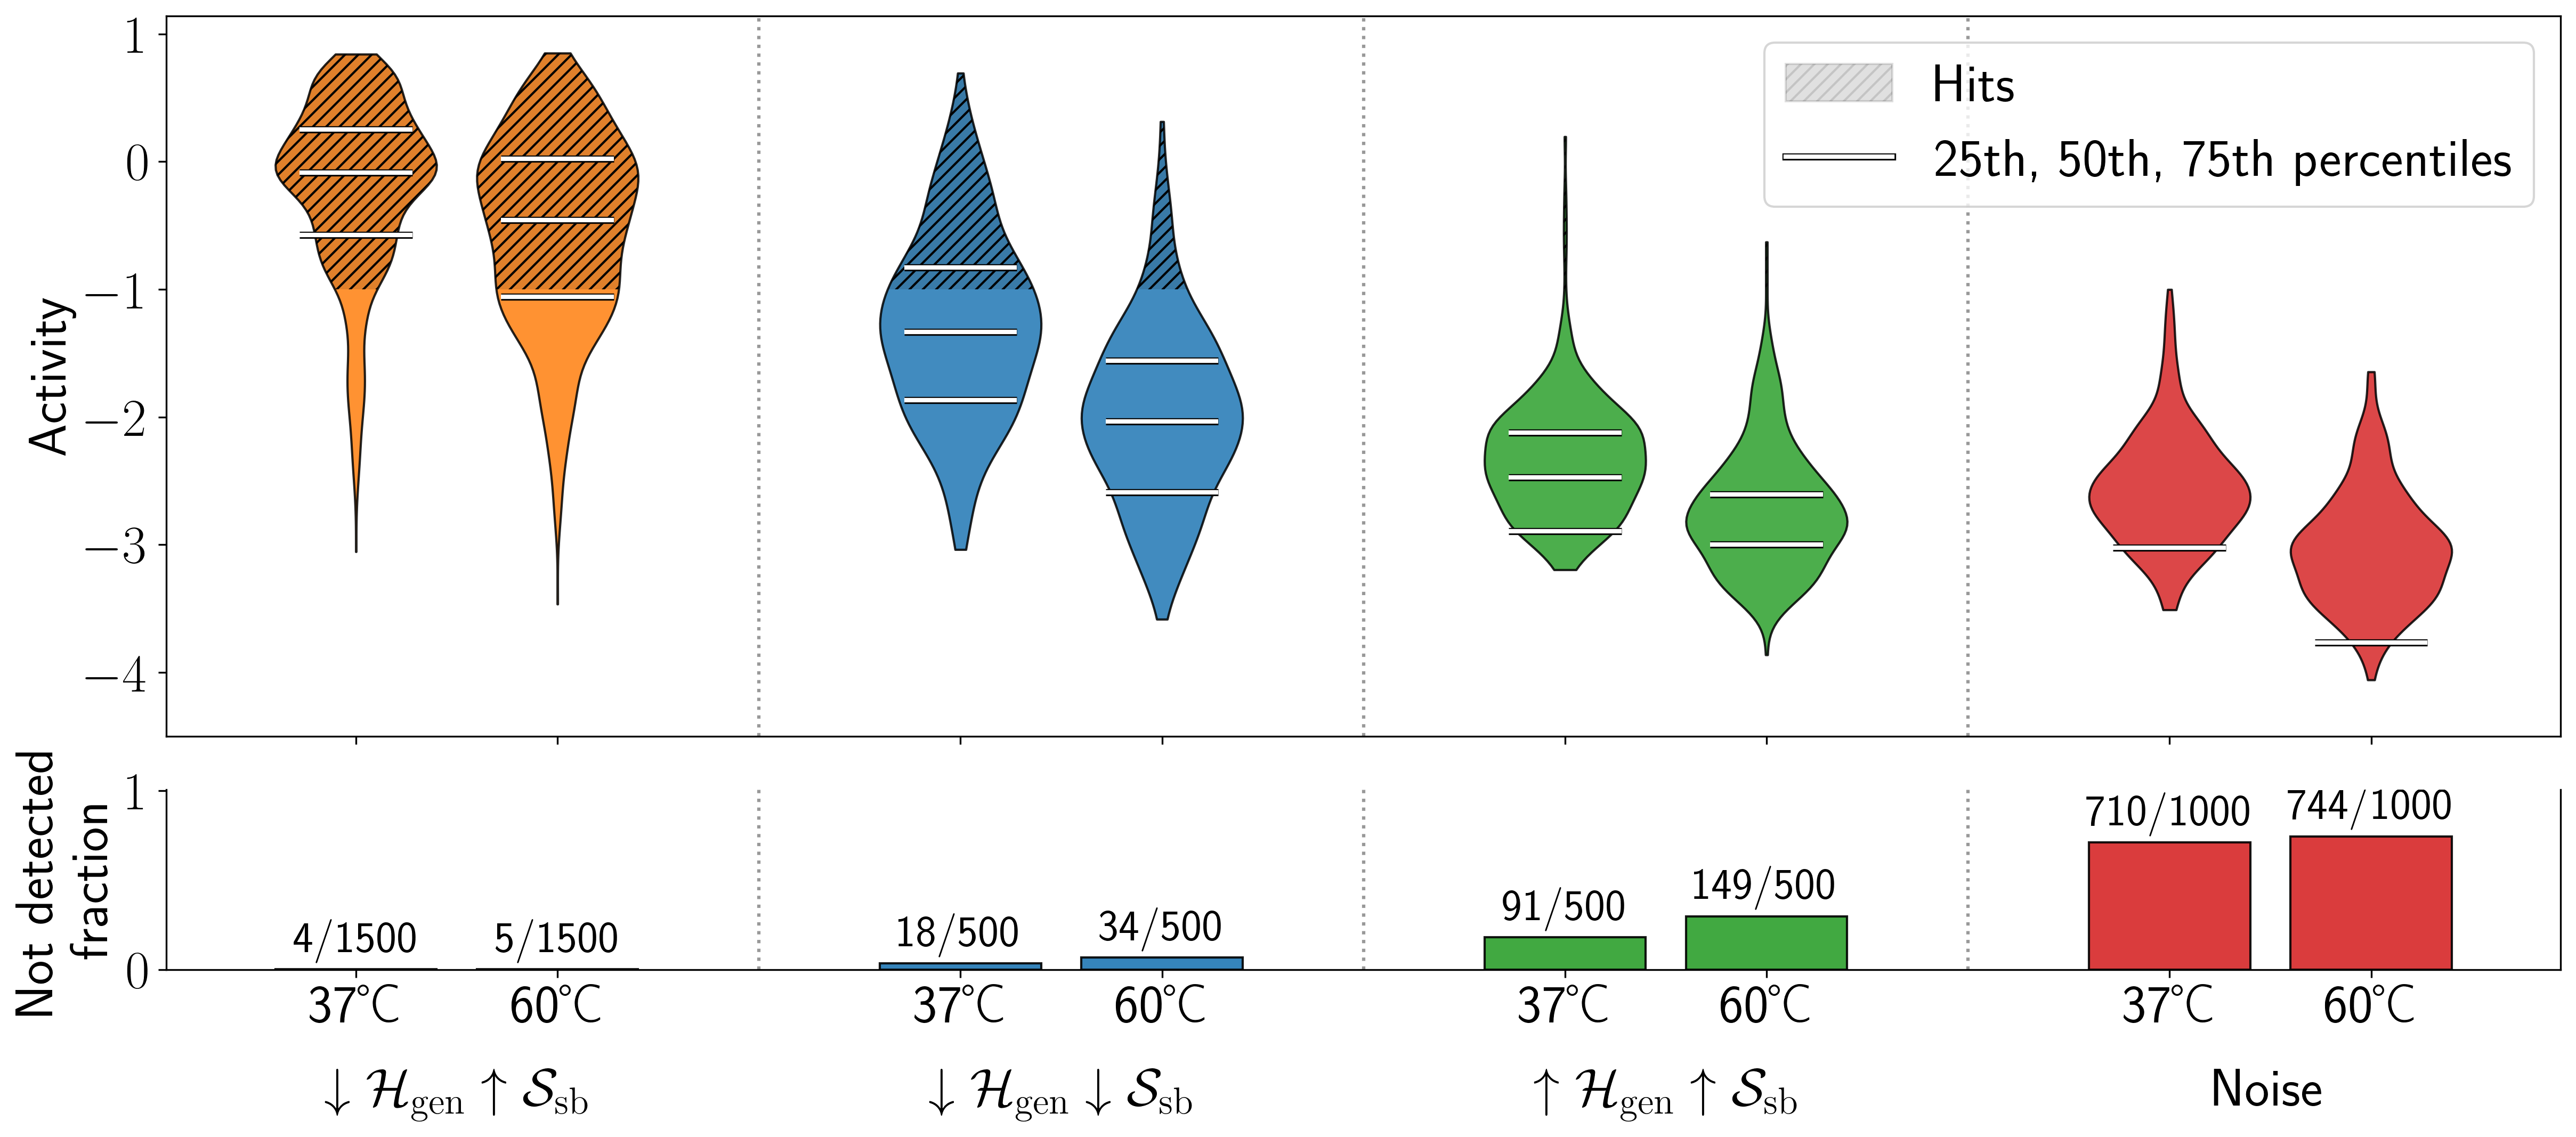

In [55]:
import matplotlib.patheffects as pe
from matplotlib.patches import Patch

regions = ["lowDCA_highSB", "lowDCA_lowSB", "highDCA_highSB", "control"]

# Global font size for all plot text except bar annotations.
global_font_size = 24
plt.rcParams.update({"font.size": global_font_size})

# Keep bar annotations independent from global font size.
bar_annotation_font_size = 20

# Edit this dictionary to customize x-axis labels.
x_label_map = {
    "37": "37℃",
    "60": "60℃",
    "lowDCA_highSB": r"$\downarrow \mathcal{H}_\mathrm{gen} \uparrow \mathcal{S}_\mathrm{sb}$",
    "lowDCA_lowSB": r"$\downarrow \mathcal{H}_\mathrm{gen} \downarrow \mathcal{S}_\mathrm{sb}$",
    "highDCA_highSB": r"$\uparrow \mathcal{H}_\mathrm{gen} \uparrow \mathcal{S}_\mathrm{sb}$",
    "control": "Noise",
}

tab10 = sns.color_palette("tab10")
region_colors = [tab10[1], tab10[0], tab10[2], tab10[3]]  # orange, blue, green, red
palette = dict(zip(regions, region_colors))

# Fixed lower limit for hits shading (same for 37 and 60).
hits_bottom = -1.0

fig, (ax_top, ax_bottom) = plt.subplots(
    2,
    1,
    figsize=(16, 7),
    sharex=True,
    constrained_layout=True,
    gridspec_kw={"height_ratios": [4, 1], "hspace": 0.05},
    dpi=300,
)

positions = []
labels = []
pair_centers = []
current_pos = 0
violin_metadata = []
missing_fracs = []
bar_colors = []
bar_texts = []

for region in regions:
    region_df = df_all[df_all["region"] == region]

    left_pos = current_pos
    right_pos = current_pos + 1
    pair_centers.append((left_pos + right_pos) / 2)

    for pos, col, short_label in [(left_pos, "activity_37", "37"), (right_pos, "activity_60", "60")]:
        # Violin excludes undetected values (-5).
        violin_values = region_df.loc[region_df[col] != -5, col].dropna().values
        if len(violin_values) > 0:
            vp = ax_top.violinplot(
                dataset=[violin_values],
                positions=[pos],
                widths=0.8,
                showmeans=False,
                showextrema=False,
                showmedians=False,
            )

            for body in vp["bodies"]:
                body.set_facecolor(palette[region])
                body.set_edgecolor("black")
                body.set_alpha(0.85)
                violin_metadata.append((body, pos))

        # Percentiles include all values, including -5.
        pct_values = region_df[col].dropna().values
        if len(pct_values) > 0:
            q25, q50, q75 = np.percentile(pct_values, [25, 50, 75])
            pct_lines = ax_top.hlines(
                [q25, q50, q75],
                pos - 0.28,
                pos + 0.28,
                colors="white",
                linestyles="-",
                linewidth=2.0,
                zorder=6,
            )
            pct_lines.set_path_effects([
                pe.Stroke(linewidth=3.2, foreground="black"),
                pe.Normal(),
            ])

        # Fraction of undetected values (-5) for the barplot.
        total_n = region_df[col].notna().sum()
        n_minus5 = (region_df[col] == -5).sum()
        frac_minus5 = n_minus5 / total_n if total_n > 0 else np.nan
        missing_fracs.append(frac_minus5)
        bar_texts.append(f"{n_minus5}/{total_n}")
        bar_colors.append(palette[region])

        positions.append(pos)
        labels.append(x_label_map.get(short_label, short_label))

    current_pos += 3

# Add shaded region inside each violin above a fixed lower limit (hits_bottom).
ymax = ax_top.get_ylim()[1]
for body, pos in violin_metadata:
    shade_fill = plt.Rectangle(
        (pos - 0.4, hits_bottom),
        0.8,
        ymax - hits_bottom,
        facecolor="black",
        alpha=0.12,
        edgecolor="none",
        zorder=3,
    )
    shade_fill.set_clip_path(body.get_paths()[0], transform=body.get_transform())
    ax_top.add_patch(shade_fill)

    shade_hatch = plt.Rectangle(
        (pos - 0.4, hits_bottom),
        0.8,
        ymax - hits_bottom,
        facecolor="none",
        edgecolor="black",
        hatch="////",
        linewidth=0,
        zorder=4,
    )
    shade_hatch.set_clip_path(body.get_paths()[0], transform=body.get_transform())
    ax_top.add_patch(shade_hatch)

# set y-axis lower limit
ax_top.set_ylim(bottom=-4.5)

# Bottom barplot: fraction of -5 values aligned with each violin.
bars = ax_bottom.bar(positions, missing_fracs, width=0.8, color=bar_colors, edgecolor="black", alpha=0.9)
ax_bottom.set_ylabel("Not detected\nfraction")
ax_bottom.set_xticks(positions)
ax_bottom.set_xticklabels(labels)
ax_bottom.set_xlabel("")

max_frac = np.nanmax(missing_fracs) if len(missing_fracs) > 0 else np.nan
if np.isnan(max_frac) or max_frac <= 0:
    max_frac = 1.0
# Add a small headroom so labels above bars stay inside the axis.
label_headroom = max(0.03, 0.08 * max_frac)
ax_bottom.set_ylim(0, max_frac + label_headroom)
ax_bottom.margins(y=0)

# Annotate each bar with num(-5)/num(total), above the bar.
for bar, text in zip(bars, bar_texts):
    height = bar.get_height()
    if np.isnan(height):
        continue
    ax_bottom.annotate(
        text,
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=bar_annotation_font_size,
        clip_on=True,
    )

# Increase the y-axis limit of the bar plot
current_ylim = ax_bottom.get_ylim()
new_ylim = (current_ylim[0], current_ylim[1] + 0.2)
ax_bottom.set_ylim(new_ylim)

# Vertical separators between region pairs on both axes.
for x_sep in [2, 5, 8]:
    ax_top.axvline(x=x_sep, color="gray", linestyle=":", linewidth=1.5, alpha=0.8)
    ax_bottom.axvline(x=x_sep, color="gray", linestyle=":", linewidth=1.5, alpha=0.8)

ax_top.set_ylabel("Activity")
ax_top.tick_params(axis="x", which="both", labelbottom=False)

# Region labels centered under each pair (on bottom axis).
for center, region in zip(pair_centers, regions):
    ax_bottom.text(
        center,
        -0.55,
        x_label_map.get(region, region),
        transform=ax_bottom.get_xaxis_transform(),
        ha="center",
        va="top",
    )

# Legend explains semantics, not region colors.
legend_handles = [
    Patch(facecolor="black", edgecolor="black", hatch="////", alpha=0.12, label="Hits"),
    plt.Line2D(
        [0],
        [0],
        color="white",
        linewidth=2.0,
        path_effects=[pe.Stroke(linewidth=3.2, foreground="black"), pe.Normal()],
        label="25th, 50th, 75th percentiles",
    ),
]
ax_top.legend(handles=legend_handles, loc="upper right")

# hide the upper lines of the bar plot to avoid visual clutter with the legend
ax_bottom.spines["top"].set_visible(False)
plt.savefig("../../../results/Images/Group_I_intron/violin_plot_activities.pdf")
# plt.savefig("../../../results/Images/Group_I_intron/violin_plot_activities.png")
plt.show()